<a href="https://colab.research.google.com/github/muriloferreira26032007-png/intro-data-science/blob/main/projeto4_telco_churn_entrega.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# -*- coding: utf-8 -*-
"""
PROJETO 4 — TELCO CUSTOMER CHURN (VERSÃO CONSOLIDADA PARA ENTREGA)
Disciplina: Introdução à Ciência de Dados (ICMC-USP)
"""

'\nPROJETO 4 — TELCO CUSTOMER CHURN (VERSÃO CONSOLIDADA PARA ENTREGA)\nDisciplina: Introdução à Ciência de Dados (ICMC-USP)\n'

# Projeto 4 — Análise Preditiva e Interpretação de Churn em Telecomunicações (Telco Customer Churn)

**Disciplina:** Introdução à Ciência de Dados (ICMC-USP)  
**Objetivo:** Desenvolver e comparar modelos supervisionados para prever o cancelamento de clientes (*churn*), avaliar estratégias de tratamento de desbalanceamento sob protocolo livre de vazamento de dados (*data leakage*), analisar o impacto operacional do limiar de decisão e discutir os principais fatores associados ao risco de evasão com foco em tomada de decisão orientada a retenção.

---

### Estrutura do Projeto
1. **Preparação e Limpeza dos Dados** — Auditoria de tipos, valores ausentes ocultos em `TotalCharges`, duplicatas e exclusão justificada de `customerID`.
2. **Análise Exploratória de Dados (EDA)** — Proporção global de *churn*, estatísticas descritivas, distribuição de contratos, serviços, formas de pagamento, cobranças e correlações numéricas.
3. **Seleção, Redundâncias, Engenharia de Atributos e Divisão Estratificada** — *Split* 80/20 estratificado prévio, diagnóstico de redundâncias estruturais e colinearidade (VIF) e teste empírico em validação cruzada (CV).
4. **Modelagem e Ajuste de Hiperparâmetros (CV sem Vazamento)** — `LogisticRegression`, `RandomForest` e `XGBoost` encapsulados em `ImbPipeline` com `GridSearchCV` (`StratifiedKFold`).
5. **Estratégias de Balanceamento** — Comparação controlada entre base original, ponderação de classes (`class_weight` / `scale_pos_weight`), *oversampling* (`SMOTE`) e *undersampling* (`RandomUnderSampler`).
6. **Avaliação no Conjunto de Teste, Limiar de Decisão e Campanha Top 10%** — Matriz de confusão, Precision, Recall, F1, ROC-AUC, Average Precision, curvas ROC/PR e simulação de retenção.
7. **Interpretação, Consistência entre Modelos e Discussão Crítica** — Comparação de importâncias entre os três algoritmos, associação estatística vs. causalidade e respostas às questões norteadoras.

In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None)

## 1. Preparação e Limpeza dos Dados

O conjunto *Telco Customer Churn* reúne **7.043 clientes** e **21 colunas** originais (identificador, características demográficas, tempo de permanência, serviços contratados, faturamento e a variável-alvo `Churn`).

Nesta etapa realizamos:
- Conversão explícita de `TotalCharges` para formato numérico (`float`), revelando **11 registros** armazenados no CSV como strings de espaço em branco (`" "`);
- Verificação de que 100% desses 11 clientes possuem **`tenure == 0`** (clientes recém-ingressados antes do fechamento da primeira fatura acumulada), o que fundamenta a imputação exata de `TotalCharges = 0.0` sem descarte de observações;
- Verificação de registros duplicados exatos e criação da variável-alvo binária (`Churn_Binario`: `Yes -> 1`, `No -> 0`);
- Exclusão justificada de **`customerID`**, pois trata-se de identificador único arbitrário (7.043 categorias distintas) sem poder de generalização para novos clientes e que provocaria sobreajuste extremo ou explosão dimensional se codificado.

In [3]:
GITHUB_URL = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
)

df_raw = pd.read_csv(GITHUB_URL)
print(f"Dimensão original: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")
print("\nTipos originais das colunas:")
print(df_raw.dtypes)

df = df_raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

auditoria_nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "percentual_%": (df.isna().sum() / len(df) * 100).round(4),
})
print("\nColunas com valores ausentes após conversão numérica de TotalCharges:")
display(auditoria_nulos[auditoria_nulos["nulos"] > 0])

print(f"Registros duplicados exatos: {df.duplicated().sum()}")
print(f"Valores únicos de customerID: {df['customerID'].nunique()} (em {len(df)} linhas)")

linhas_nulas = df[df["TotalCharges"].isna()][
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]
]
print("\nRegistros com TotalCharges originalmente em branco (todos com tenure == 0):")
display(linhas_nulas)
assert (linhas_nulas["tenure"] == 0).all()

# Imputação semanticamente consistente: tenure == 0 => cobrança acumulada inicial = 0.0
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)
df["Churn_Binario"] = df["Churn"].map({"Yes": 1, "No": 0})
df["SeniorCitizen_Label"] = df["SeniorCitizen"].map({1: "Yes", 0: "No"})

assert df.isna().sum().sum() == 0, "Ainda existem valores ausentes!"
display(df.head())

Dimensão original: 7043 linhas x 21 colunas

Tipos originais das colunas:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Colunas com valores ausentes após conversão numérica de TotalCharges:


,nulos,percentual_%
TotalCharges,11,0.1562


Registros duplicados exatos: 0
Valores únicos de customerID: 7043 (em 7043 linhas)

Registros com TotalCharges originalmente em branco (todos com tenure == 0):


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,NaN,Two year,No
753,3115-CZMZD,0,20.25,NaN,Two year,No
936,5709-LVOEQ,0,80.85,NaN,Two year,No
1082,4367-NUYAO,0,25.75,NaN,Two year,No
1340,1371-DWPAZ,0,56.05,NaN,Two year,No
3331,7644-OMVMY,0,19.85,NaN,Two year,No
3826,3213-VVOLG,0,25.35,NaN,Two year,No
4380,2520-SGTTA,0,20.00,NaN,Two year,No
5218,2923-ARZLG,0,19.70,NaN,One year,No
6670,4075-WKNIU,0,73.35,NaN,Two year,No


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_Binario,SeniorCitizen_Label
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,No
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,No


## 2. Análise Exploratória de Dados (EDA)

A análise descritiva orienta a formulação de hipóteses antes da modelagem:
- **Desbalanceamento da classe alvo:** cerca de **73,46%** (`5.174`) dos clientes permaneceram ativos (`No`) e **26,54%** (`1.869`) cancelaram (`Yes`), caracterizando desbalanceamento moderado no qual acurácia bruta pode mascarar baixa captura da classe minoritária.
- **Variáveis numéricas:** clientes que cancelam apresentam mediana de `tenure` muito menor (`10` meses contra `38` meses dos retidos) e mediana de `MonthlyCharges` mais elevada (`79,65` contra `64,43`). Como `TotalCharges ≈ tenure × MonthlyCharges`, sua correlação marginal com `Churn` é negativa (`-0,1995`), refletindo o efeito dominante do menor tempo de permanência entre quem evade.
- **Segmentos contratuais e operacionais:** contratos mensais (`Month-to-month`), internet em fibra óptica (`Fiber optic`), pagamento via cheque eletrônico (`Electronic check`) e ausência de serviços de suporte/segurança (`TechSupport = No`, `OnlineSecurity = No`) concentram as maiores taxas relativas de cancelamento.

Distribuição Global de Churn:


,contagem,percentual_%
Churn,,
No,5174,73.46
Yes,1869,26.54



Estatísticas numéricas segmentadas por Churn:


tenure                              MonthlyCharges                       \
       count   mean median    std min max          count   mean median    std   
Churn                                                                           
No      5174  37.57   38.0  24.11   0  72           5174  61.27  64.43  31.09   
Yes     1869  17.98   10.0  19.53   1  72           1869  74.44  79.65  24.67   

                     TotalCharges                                             
         min     max        count     mean   median      std    min      max  
Churn                                                                         
No     18.25  118.75         5174  2549.91  1679.52  2329.95   0.00  8672.45  
Yes    18.85  118.35         1869  1531.80   703.55  1890.82  18.85  8684.80

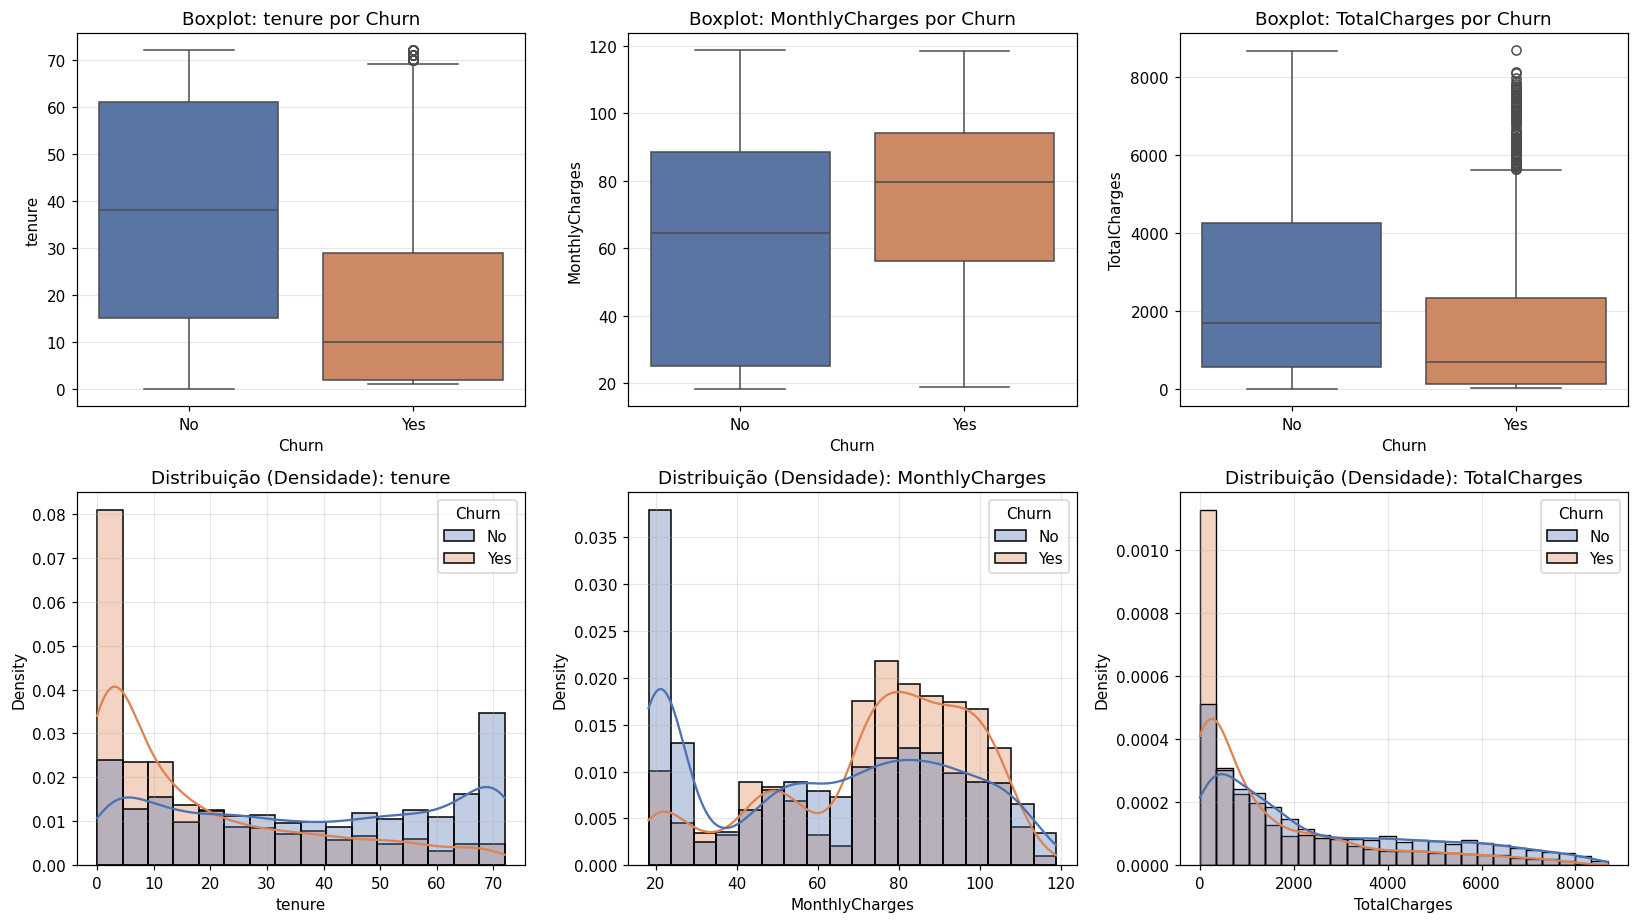

Resumo de Churn (%) e tamanho amostral por categoria:

--- Contract ---


,n,churns,pct_base,taxa_churn_pct
Contract,,,,
Month-to-month,3875,1655,55.02,42.71
One year,1473,166,20.91,11.27
Two year,1695,48,24.07,2.83



--- InternetService ---


,n,churns,pct_base,taxa_churn_pct
InternetService,,,,
Fiber optic,3096,1297,43.96,41.89
DSL,2421,459,34.37,18.96
No,1526,113,21.67,7.40



--- PaymentMethod ---


,n,churns,pct_base,taxa_churn_pct
PaymentMethod,,,,
Electronic check,2365,1071,33.58,45.29
Mailed check,1612,308,22.89,19.11
Bank transfer (automatic),1544,258,21.92,16.71
Credit card (automatic),1522,232,21.61,15.24


... (22 outputs left out)


--- MultipleLines ---


,n,churns,pct_base,taxa_churn_pct
MultipleLines,,,,
Yes,2971,850,42.18,28.61
No,3390,849,48.13,25.04
No phone service,682,170,9.68,24.93



--- gender ---


,n,churns,pct_base,taxa_churn_pct
gender,,,,
Female,3488,939,49.52,26.92
Male,3555,930,50.48,26.16


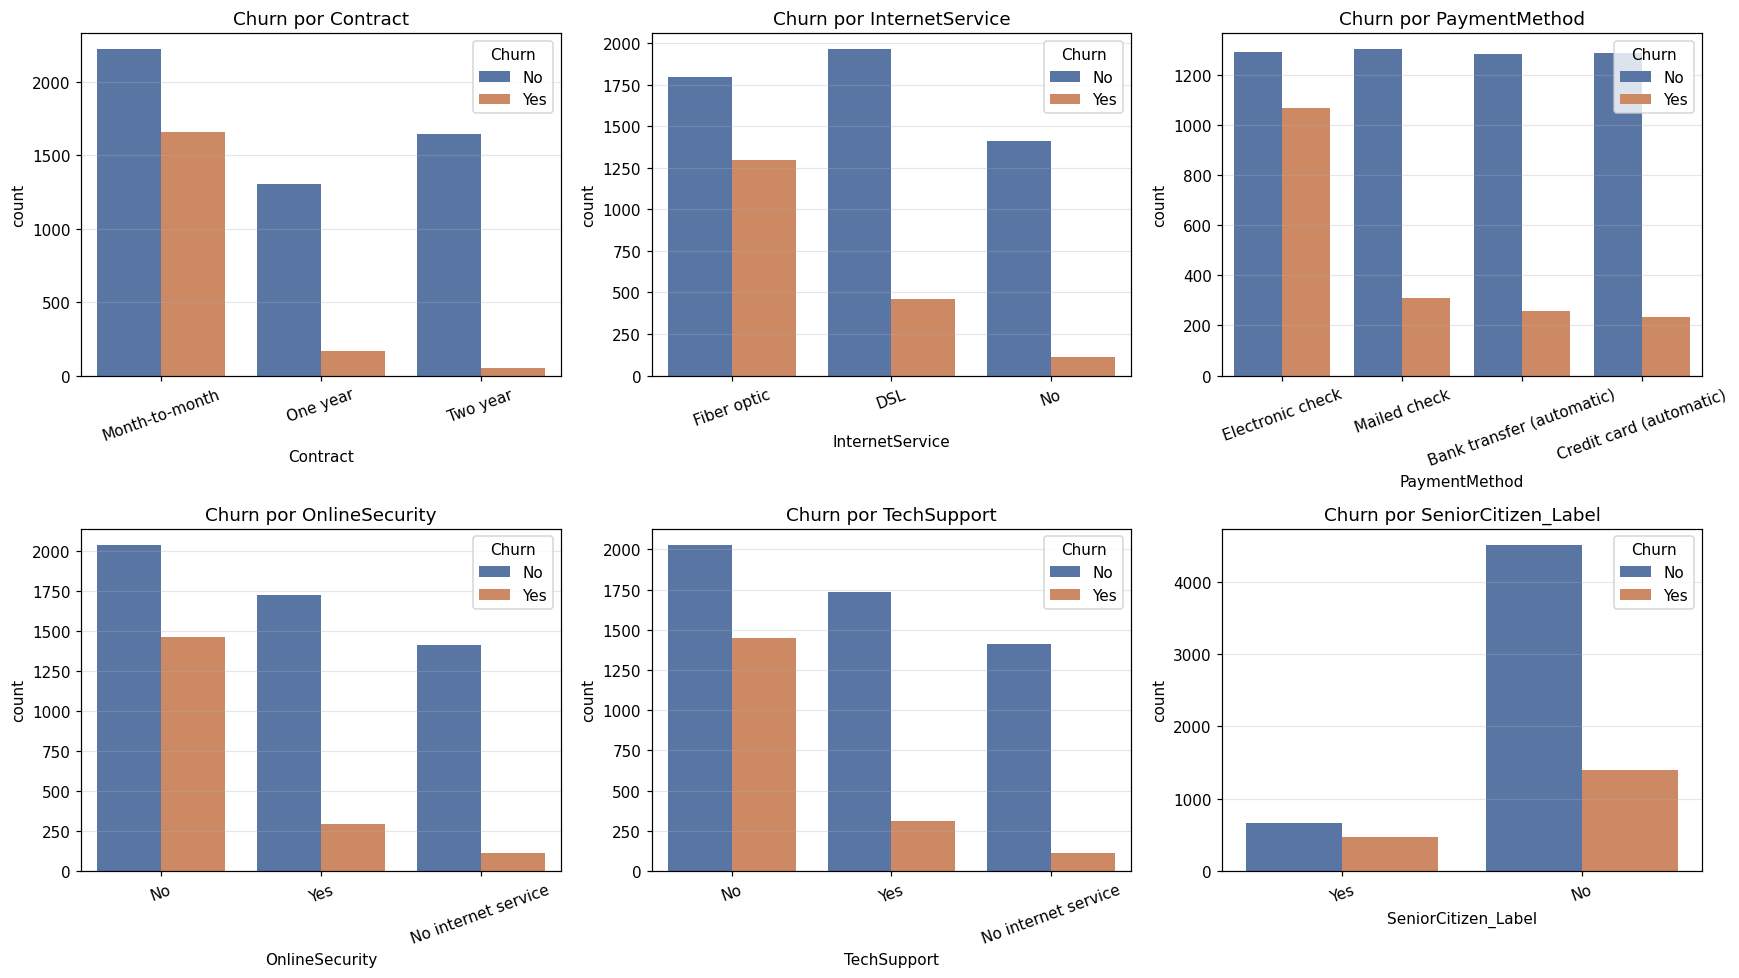


Correlação linear (Pearson) — Variáveis numéricas:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn_Binario
SeniorCitizen,1.0000,0.0166,0.2202,0.1030,0.1509
tenure,0.0166,1.0000,0.2479,0.8262,-0.3522
MonthlyCharges,0.2202,0.2479,1.0000,0.6512,0.1934
TotalCharges,0.1030,0.8262,0.6512,1.0000,-0.1983
Churn_Binario,0.1509,-0.3522,0.1934,-0.1983,1.0000


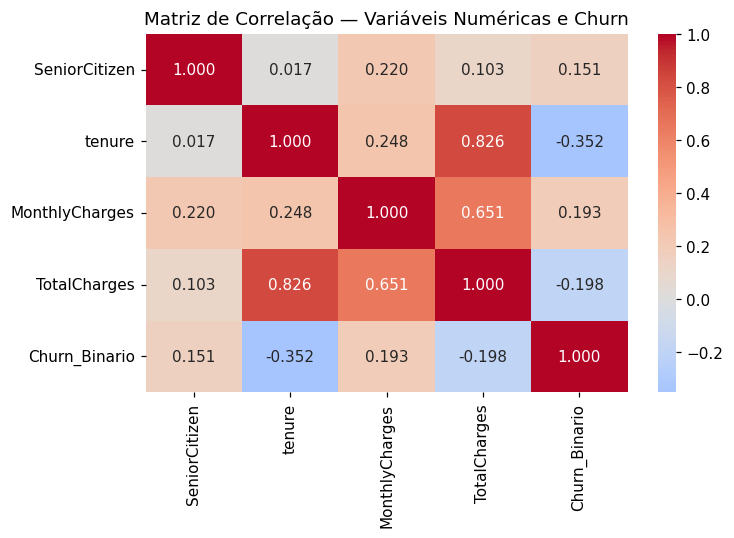

In [4]:
# 2.1 Proporção global do alvo
tabela_alvo = pd.DataFrame({
    "contagem": df["Churn"].value_counts(),
    "percentual_%": (df["Churn"].value_counts(normalize=True) * 100).round(2),
})
print("Distribuição Global de Churn:")
display(tabela_alvo)

# 2.2 Estatísticas descritivas numéricas por classe
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
print("\nEstatísticas numéricas segmentadas por Churn:")
display(df.groupby("Churn")[num_cols].agg(["count", "mean", "median", "std", "min", "max"]).round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for col_idx, col in enumerate(num_cols):
    sns.boxplot(
        data=df, x="Churn", y=col, hue="Churn",
        palette={"No": "#4C72B0", "Yes": "#DD8452"}, legend=False, ax=axes[0, col_idx]
    )
    axes[0, col_idx].set_title(f"Boxplot: {col} por Churn")
    axes[0, col_idx].grid(axis="y", alpha=0.3)

    sns.histplot(
        data=df, x=col, hue="Churn", kde=True, stat="density", common_norm=False,
        palette={"No": "#4C72B0", "Yes": "#DD8452"}, alpha=0.35, ax=axes[1, col_idx]
    )
    axes[1, col_idx].set_title(f"Distribuição (Densidade): {col}")
    axes[1, col_idx].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 2.3 Taxa de Churn e tamanho dos grupos (n) em todas as variáveis categóricas
todas_categoricas = [
    "Contract", "InternetService", "PaymentMethod",
    "OnlineSecurity", "TechSupport", "OnlineBackup", "DeviceProtection",
    "StreamingTV", "StreamingMovies", "PaperlessBilling",
    "SeniorCitizen_Label", "Partner", "Dependents",
    "PhoneService", "MultipleLines", "gender",
]

print("Resumo de Churn (%) e tamanho amostral por categoria:")
for col in todas_categoricas:
    resumo_cat = (
        df.groupby(col)["Churn_Binario"]
        .agg(n="count", churns="sum", taxa="mean")
        .assign(
            pct_base=lambda d: (d["n"] / len(df) * 100).round(2),
            taxa_churn_pct=lambda d: (d["taxa"] * 100).round(2),
        )
        .drop(columns="taxa")
        .sort_values("taxa_churn_pct", ascending=False)
    )
    print(f"\n--- {col} ---")
    display(resumo_cat)

# Painel visual dos principais direcionadores categóricos
principais_cats = [
    "Contract", "InternetService", "PaymentMethod",
    "OnlineSecurity", "TechSupport", "SeniorCitizen_Label",
]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), principais_cats):
    ordem = df.groupby(col)["Churn_Binario"].mean().sort_values(ascending=False).index
    sns.countplot(
        data=df, x=col, hue="Churn", order=ordem,
        palette={"No": "#4C72B0", "Yes": "#DD8452"}, ax=ax
    )
    ax.set_title(f"Churn por {col}")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 2.4 Matriz de correlação numérica
cols_corr = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "Churn_Binario"]
corr_mat = df[cols_corr].corr()
print("\nCorrelação linear (Pearson) — Variáveis numéricas:")
display(corr_mat.round(4))

plt.figure(figsize=(7, 5))
sns.heatmap(corr_mat, annot=True, fmt=".3f", cmap="coolwarm", center=0)
plt.title("Matriz de Correlação — Variáveis Numéricas e Churn")
plt.tight_layout()
plt.show()

## 3. Divisão Estratificada, Investigação de Redundâncias e Engenharia de Atributos

Para cumprir rigorosamente os cuidados metodológicos contra **vazamento de dados**:
1. Realizamos o `train_test_split` estratificado (**80% treino / 20% teste**) **antes** de calcular escalas (`StandardScaler`), codificadores (`OneHotEncoder`), estatísticas de colinearidade (VIF) ou validações de seleção de variáveis;
2. Investigamos duas redundâncias estruturais relevantes no conjunto de treino:
   - **Redundância perfeita pós-*One-Hot Encoding*:** o nível `"No phone service"` em `MultipleLines` é exatamente idêntico a `PhoneService == "No"`, e o nível `"No internet service"` repete-se identicamente em **6 colunas** (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`), duplicando `InternetService == "No"`.
   - **Multicolinearidade numérica:** `TotalCharges` é aproximadamente o produto `tenure × MonthlyCharges`, gerando alto VIF e instabilidade de sinais em coeficientes lineares quando todas atuam em conjunto; além disso, avaliamos se `gender` agrega poder preditivo relevante em validação cruzada (conforme observado na tabela da Seção 2.3).
3. Executamos um experimento em **Validação Cruzada Estratificada (5 folds)** apenas no treino comparando:
   - `1_Base_Completa`: todas as 19 preditoras válidas com `OneHotEncoder(drop="first")` + `StandardScaler`;
   - `2_Sem_Redundancias`: colapso dos níveis redundantes (`"No internet service"` e `"No phone service"` mapeados para `"No"`) + remoção de `gender` e `TotalCharges`;
   - `3_Engenharia_Features`: criação de `ServicesCount` (quantidade de serviços contratados), `AvgMonthlySpend` (`TotalCharges / max(tenure, 1)`), `ChargePerService` e `IsNewCustomer` (`tenure <= 6`), mantendo remoção das colunas redundantes.

In [5]:
# Remoção exclusiva de identificador e colunas auxiliares de texto
X_full = df.drop(columns=["customerID", "Churn", "Churn_Binario", "SeniorCitizen_Label"])
y = df["Churn_Binario"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X_full, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Treino: {X_train.shape} | Taxa de Churn = {y_train.mean()*100:.2f}%")
print(f"Teste:  {X_test.shape} | Taxa de Churn = {y_test.mean()*100:.2f}%")

# Diagnóstico de colinearidade (VIF) exclusivamente no TREINO
def calcular_vif(df_num: pd.DataFrame) -> pd.DataFrame:
    vifs = []
    for c in df_num.columns:
        X_outros = df_num.drop(columns=[c])
        r2 = LinearRegression().fit(X_outros, df_num[c]).score(X_outros, df_num[c])
        vif = np.inf if r2 >= 0.999999 else 1.0 / (1.0 - r2)
        vifs.append({"variavel": c, "R2_contra_outras": round(r2, 4), "VIF": round(vif, 2)})
    return pd.DataFrame(vifs)

print("\nDiagnóstico VIF (Multicolinearidade Numérica no Treino):")
display(calcular_vif(X_train[["tenure", "MonthlyCharges", "TotalCharges"]]))

cols_internet_addons = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]

redund_internet = all(
    ((X_train[c] == "No internet service") == (X_train["InternetService"] == "No")).all()
    for c in cols_internet_addons
)
redund_fone = (
    (X_train["MultipleLines"] == "No phone service") == (X_train["PhoneService"] == "No")
).all()
print(f"6 colunas 'No internet service' são 100% idênticas a InternetService=='No'? {redund_internet}")
print(f"Coluna 'No phone service' é 100% idêntica a PhoneService=='No'?            {redund_fone}")


def preparar_representacao(df_in: pd.DataFrame, modo: str) -> pd.DataFrame:
    '''Transformação determinística linha a linha (sem uso de estatísticas globais).'''
    out = df_in.copy()
    if modo == "1_Base_Completa":
        return out

    for c in cols_internet_addons:
        out[c] = out[c].replace({"No internet service": "No"})
    out["MultipleLines"] = out["MultipleLines"].replace({"No phone service": "No"})

    if modo == "2_Sem_Redundancias":
        return out.drop(columns=["gender", "TotalCharges"])

    if modo == "3_Engenharia_Features":
        servicos = cols_internet_addons + ["PhoneService", "MultipleLines"]
        out["ServicesCount"] = sum((out[c] == "Yes").astype(int) for c in servicos)
        out["AvgMonthlySpend"] = out["TotalCharges"] / np.maximum(out["tenure"], 1)
        out["ChargePerService"] = out["MonthlyCharges"] / (out["ServicesCount"] + 1)
        out["IsNewCustomer"] = (out["tenure"] <= 6).astype(int)
        return out.drop(columns=["gender", "TotalCharges"])

    raise ValueError(f"Modo desconhecido: {modo}")


def criar_preprocessador(df_exemplo: pd.DataFrame) -> ColumnTransformer:
    num_c = df_exemplo.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns.tolist()
    cat_c = df_exemplo.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_c),
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_c),
        ],
        verbose_feature_names_out=False,
    )


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
ablation_rows = []

for modo in ["1_Base_Completa", "2_Sem_Redundancias", "3_Engenharia_Features"]:
    X_var = preparar_representacao(X_train, modo)
    prep_var = criar_preprocessador(X_var)
    n_pos_ohe = clone(prep_var).fit(X_var).transform(X_var.iloc[:1]).shape[1]

    for nome_clf, clf in [
        ("LogisticRegression", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
        ("XGBoost", XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1)),
    ]:
        pipe_var = ImbPipeline([("prep", clone(prep_var)), ("clf", clf)])
        cv_out = cross_validate(
            pipe_var, X_var, y_train, cv=cv,
            scoring={"roc_auc": "roc_auc", "ap": "average_precision"}, n_jobs=-1
        )
        ablation_rows.append({
            "Representacao": modo,
            "Modelo": nome_clf,
            "Dimensao_Pos_OHE": int(n_pos_ohe),
            "CV_ROC_AUC_Mean": cv_out["test_roc_auc"].mean(),
            "CV_ROC_AUC_Std": cv_out["test_roc_auc"].std(),
            "CV_AP_Mean": cv_out["test_ap"].mean(),
            "CV_AP_Std": cv_out["test_ap"].std(),
        })

ablation_df = pd.DataFrame(ablation_rows).sort_values(["Modelo", "CV_AP_Mean"], ascending=[True, False])
print("\nResultado em CV (5 folds) — Impacto de Remoção de Redundâncias e Engenharia:")
display(ablation_df.round(4))

# Seleção estritamente guiada pela média CV Average Precision no conjunto de treino (zero leakage)
resumo_modos = ablation_df.groupby("Representacao")["CV_AP_Mean"].mean().sort_values(ascending=False)
MODO_ESCOLHIDO = resumo_modos.index[0]
print(f"\nRepresentação com maior Average Precision médio em CV: {MODO_ESCOLHIDO}")

Treino: (5634, 19) | Taxa de Churn = 26.54%
Teste:  (1409, 19) | Taxa de Churn = 26.54%

Diagnóstico VIF (Multicolinearidade Numérica no Treino):


,variavel,R2_contra_outras,VIF
0,tenure,0.8314,5.93
1,MonthlyCharges,0.6904,3.23
2,TotalCharges,0.8967,9.68


6 colunas 'No internet service' são 100% idênticas a InternetService=='No'? True
Coluna 'No phone service' é 100% idêntica a PhoneService=='No'?            True

Resultado em CV (5 folds) — Impacto de Remoção de Redundâncias e Engenharia:


,Representacao,Modelo,Dimensao_Pos_OHE,CV_ROC_AUC_Mean,CV_ROC_AUC_Std,CV_AP_Mean,CV_AP_Std
4,3_Engenharia_Features,LogisticRegression,25,0.8477,0.0113,0.6615,0.0153
0,1_Base_Completa,LogisticRegression,30,0.8462,0.0126,0.6615,0.0192
2,2_Sem_Redundancias,LogisticRegression,21,0.8451,0.0121,0.6601,0.0181
1,1_Base_Completa,XGBoost,30,0.8258,0.0077,0.6248,0.0141
3,2_Sem_Redundancias,XGBoost,21,0.8207,0.0074,0.6212,0.0209
5,3_Engenharia_Features,XGBoost,25,0.8201,0.0112,0.6170,0.0127



Representação com maior Average Precision médio em CV: 1_Base_Completa


## 4 & 5. Modelagem Supervisionada, Hiperparâmetros e Estratégias de Balanceamento

Comparamos **3 famílias de classificadores** (`LogisticRegression`, `RandomForest` e `XGBoost`) sob **4 cenários de desbalanceamento** usando exatamente o mesmo protocolo experimental:
1. **`1_Original`** — distribuição natural de treino (~73,5% vs. ~26,5%);
2. **`2_Class_Weight`** — penalização proporcional inversa à frequência das classes (`class_weight="balanced"` / `scale_pos_weight`);
3. **`3_SMOTE`** — *oversampling* sintético da classe minoritária aplicado **apenas** nos folds de treino via `imblearn.pipeline.Pipeline`;
4. **`4_Undersampling`** — subamostragem aleatória da classe majoritária (`RandomUnderSampler`) aplicada **apenas** nos folds de treino.

Todos os hiperparâmetros são selecionados via `GridSearchCV` com `StratifiedKFold(n_splits=5)` maximizando **`average_precision`** (área sob a curva Precision-Recall), critério mais informativo que a acurácia sob desbalanceamento. O conjunto de teste permanece intocado até a avaliação final.

In [6]:
X_tr_mod = preparar_representacao(X_train, MODO_ESCOLHIDO)
X_te_mod = preparar_representacao(X_test, MODO_ESCOLHIDO)
preprocessador = criar_preprocessador(X_tr_mod)

# Razão de desbalanceamento calculada exclusivamente no conjunto de treino
scale_pos = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"Fator scale_pos_weight (y_train): {scale_pos:.4f} | Representação ativa: {MODO_ESCOLHIDO}")

estrategias = {
    "1_Original": None,
    "2_Class_Weight": "class_weight",
    "3_SMOTE": SMOTE(random_state=RANDOM_STATE),
    "4_Undersampling": RandomUnderSampler(random_state=RANDOM_STATE),
}

modelos_grids = {
    "LogisticRegression": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {"clf__C": [0.01, 0.1, 1.0, 10.0]},
    ),
    "RandomForest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        {"clf__n_estimators": [200, 300], "clf__max_depth": [6, 10, 14]},
    ),
    "XGBoost": (
        XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1),
        {"clf__n_estimators": [150, 250], "clf__max_depth": [3, 5], "clf__learning_rate": [0.05, 0.1]},
    ),
}

resultados = []
melhores_pipelines = {}

for est_nome, est_obj in estrategias.items():
    for mod_nome, (mod_base, grid) in modelos_grids.items():
        clf = clone(mod_base)
        sampler_step = "passthrough"

        if est_obj == "class_weight":
            if mod_nome == "XGBoost":
                clf.set_params(scale_pos_weight=scale_pos)
            else:
                clf.set_params(class_weight="balanced")
        elif est_obj is not None:
            sampler_step = clone(est_obj)

        pipe = ImbPipeline([
            ("prep", clone(preprocessador)),
            ("sampler", sampler_step),
            ("clf", clf),
        ])

        gs = GridSearchCV(
            estimator=pipe,
            param_grid=grid,
            cv=cv,
            scoring="average_precision",
            n_jobs=-1,
        )
        gs.fit(X_tr_mod, y_train)

        best_pipe = gs.best_estimator_
        melhores_pipelines[(est_nome, mod_nome)] = best_pipe

        y_pred = best_pipe.predict(X_te_mod)
        y_prob = best_pipe.predict_proba(X_te_mod)[:, 1]

        resultados.append({
            "Estrategia": est_nome,
            "Modelo": mod_nome,
            "Melhores_Params": gs.best_params_,
            "CV_AP": gs.best_score_,
            "Test_Precision": precision_score(y_test, y_pred, zero_division=0),
            "Test_Recall": recall_score(y_test, y_pred),
            "Test_F1": f1_score(y_test, y_pred),
            "Test_ROC_AUC": roc_auc_score(y_test, y_prob),
            "Test_AP": average_precision_score(y_test, y_prob),
        })

df_resultados = (
    pd.DataFrame(resultados)
    .sort_values(["Test_AP", "Test_ROC_AUC"], ascending=False)
    .reset_index(drop=True)
)
print("\nTabela Comparativa Geral no Conjunto de Teste (ordenada por Test_AP):")
display(df_resultados.drop(columns=["Melhores_Params"]).round(4))

print("\nMelhores Hiperparâmetros (selecionados exclusivamente em CV):")
for _, row in df_resultados.iterrows():
    print(f" - {row['Estrategia']:16s} | {row['Modelo']:18s} -> {row['Melhores_Params']}")

Fator scale_pos_weight (y_train): 2.7686 | Representação ativa: 1_Base_Completa

Tabela Comparativa Geral no Conjunto de Teste (ordenada por Test_AP):


,Estrategia,Modelo,CV_AP,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC,Test_AP
0,1_Original,XGBoost,0.6674,0.6610,0.5160,0.5796,0.8459,0.6638
1,4_Undersampling,XGBoost,0.6607,0.5068,0.7995,0.6203,0.8448,0.6602
2,2_Class_Weight,XGBoost,0.6663,0.5077,0.7941,0.6194,0.8407,0.6597
3,4_Undersampling,RandomForest,0.6577,0.5050,0.8048,0.6206,0.8432,0.6551
4,1_Original,RandomForest,0.6615,0.6667,0.4385,0.5290,0.8434,0.6546
5,3_SMOTE,XGBoost,0.6615,0.5673,0.6765,0.6171,0.8424,0.6530
6,2_Class_Weight,RandomForest,0.6578,0.5102,0.8048,0.6245,0.8428,0.6435
7,3_SMOTE,RandomForest,0.6507,0.5441,0.7086,0.6156,0.8415,0.6429
8,1_Original,LogisticRegression,0.6615,0.6604,0.5615,0.6069,0.8422,0.6350
9,4_Undersampling,LogisticRegression,0.6615,0.5113,0.7861,0.6196,0.8430,0.6347



Melhores Hiperparâmetros (selecionados exclusivamente em CV):
 - 1_Original       | XGBoost            -> {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 150}
 - 4_Undersampling  | XGBoost            -> {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 150}
 - 2_Class_Weight   | XGBoost            -> {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 150}
 - 4_Undersampling  | RandomForest       -> {'clf__max_depth': 6, 'clf__n_estimators': 300}
 - 1_Original       | RandomForest       -> {'clf__max_depth': 6, 'clf__n_estimators': 300}
 - 3_SMOTE          | XGBoost            -> {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 250}
 - 2_Class_Weight   | RandomForest       -> {'clf__max_depth': 6, 'clf__n_estimators': 200}
 - 3_SMOTE          | RandomForest       -> {'clf__max_depth': 10, 'clf__n_estimators': 300}
 - 1_Original       | LogisticRegression -> {'clf__C': 1.0}
 - 4_Undersampling  | Logisti

## 6. Avaliação no Teste, Matrizes de Confusão, Curvas ROC/PR, Limiar e Top 10%

Nesta seção avaliamos todos os resultados no conjunto de teste com distribuição original:
- **Matrizes de Confusão:** visualização explícita de Verdadeiros Positivos (churns capturados), Falsos Negativos (churns perdidos) e Falsos Positivos (custos de abordagem promocional) sob cada estratégia no algoritmo campeão;
- **Curvas ROC e Precision-Recall (PR):** comparação direta entre as 3 famílias de algoritmos **e** entre as 4 estratégias de balanceamento sobre o modelo vencedor, destacando o *baseline* aleatório na curva PR (`AP ≈ 0,2654`);
- **Sensibilidade ao Limiar de Decisão:** efeito de variar o ponto de corte de `0,15` a `0,70` nas probabilidades do modelo campeão sem reamostragem (`1_Original`, que preserva a calibração natural de risco);
- **Simulação Estratégica Top 10%:** quantos cancelamentos reais a empresa consegue capturar ao concentrar a campanha de retenção apenas nos 10% de clientes com maior risco predito.

Campeão em ordenação probabilística (Test_AP): XGBoost | 1_Original (AP=0.6638, AUC=0.8459)
Campeão em equilíbrio F1 (limiar 0.50):        RandomForest | 2_Class_Weight (F1=0.6245, Recall=0.8048)


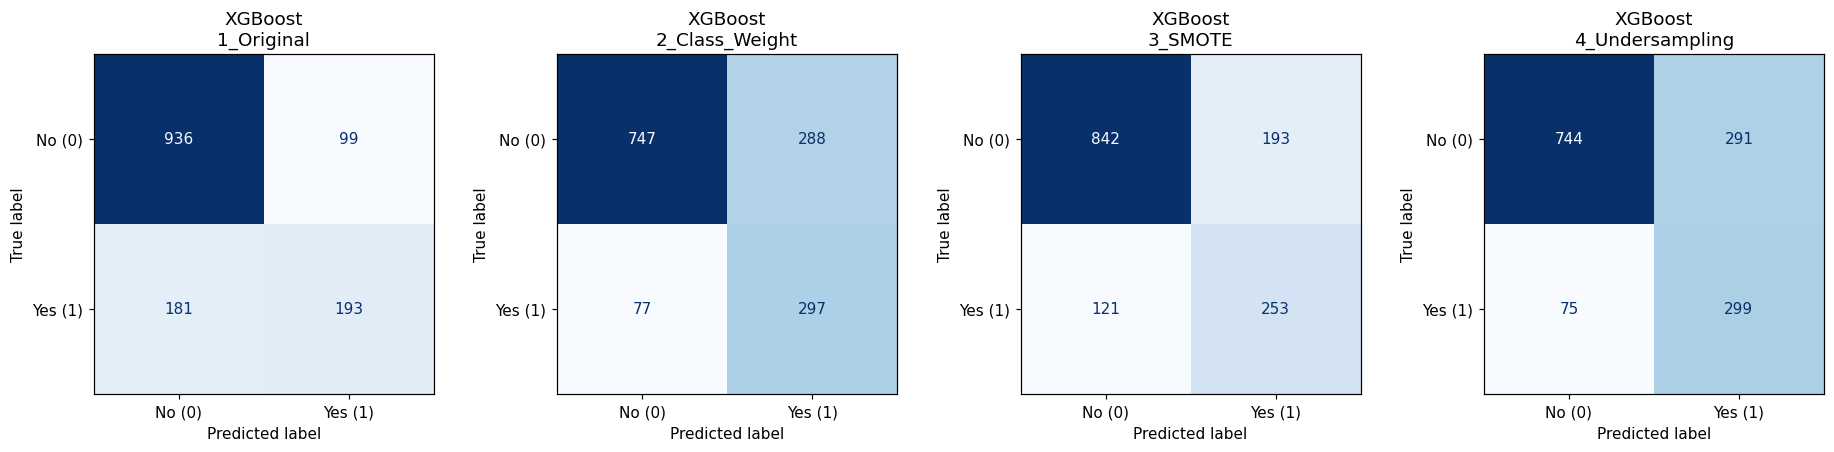


Relatório de Classificação Detalhado — RandomForest (2_Class_Weight):
              precision    recall  f1-score   support

No Churn (0)       0.91      0.72      0.80      1035
   Churn (1)       0.51      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



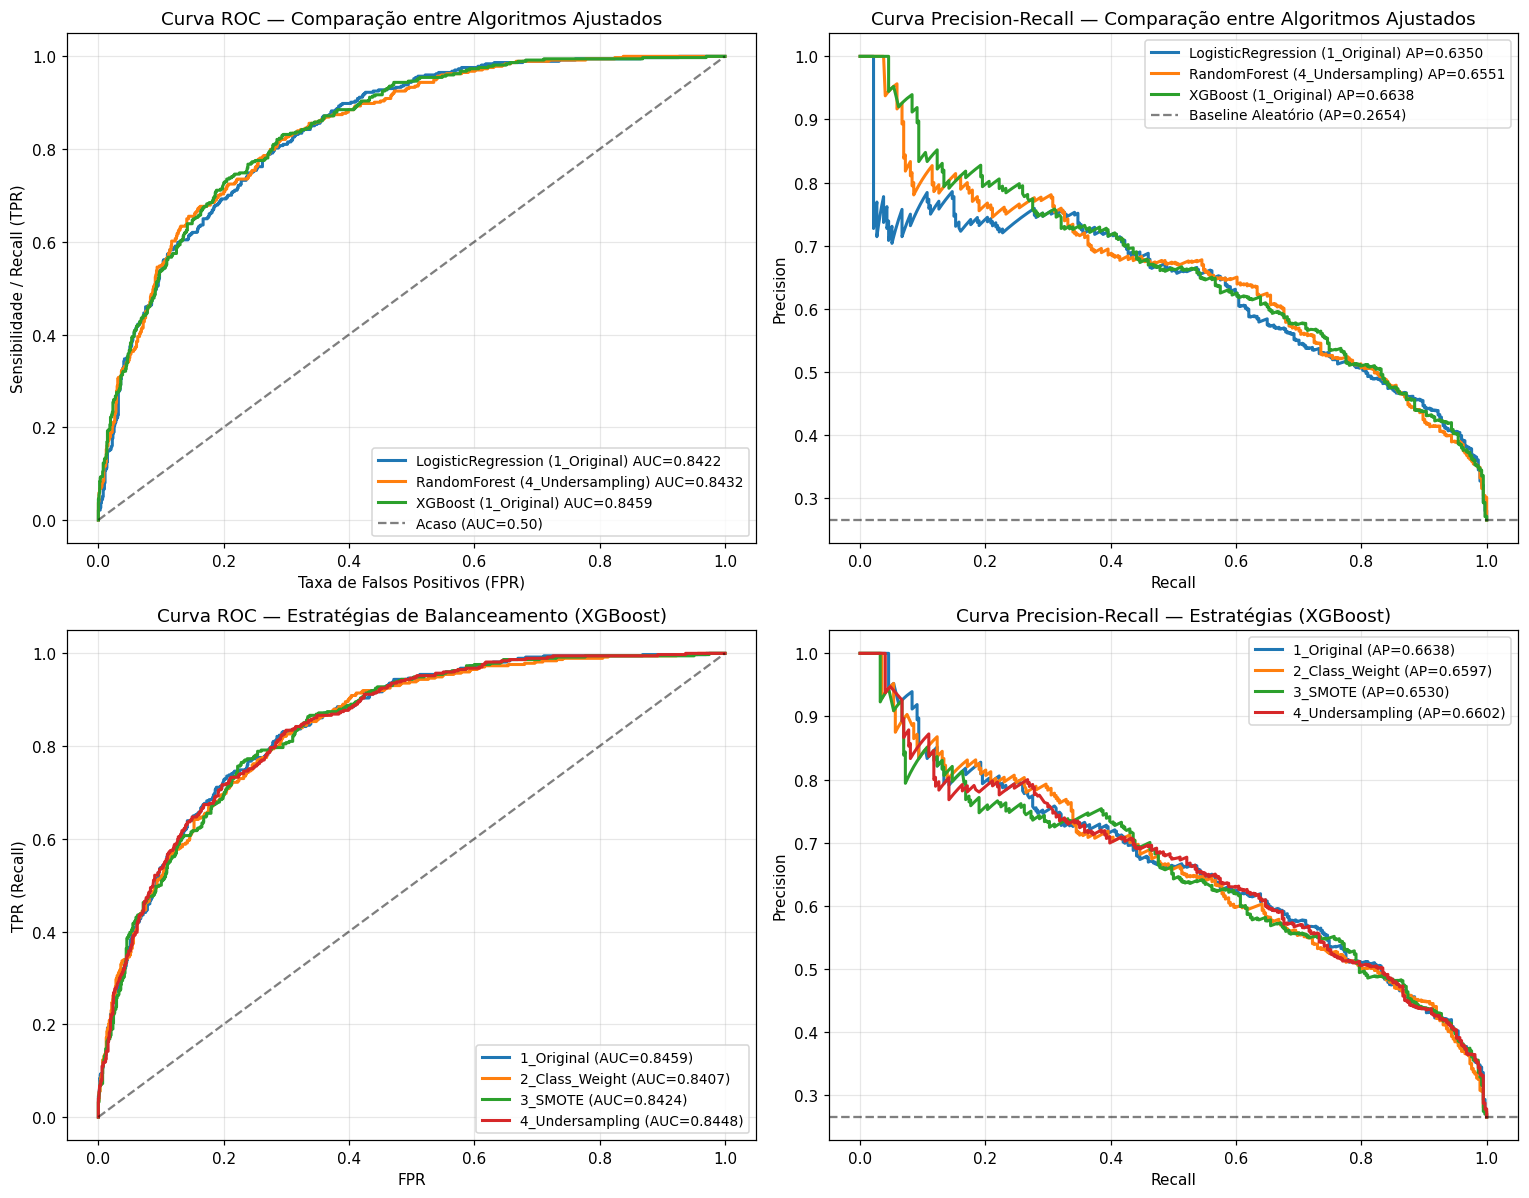

Variação do Limiar de Decisão — XGBoost (1_Original):


,Limiar,Clientes_Acionados,Pct_Base_Acionada,Precision,Recall,F1
0,0.15,774,54.93,0.4367,0.9037,0.5889
1,0.20,680,48.26,0.4721,0.8583,0.6091
2,0.25,613,43.51,0.5057,0.8289,0.6282
3,0.30,552,39.18,0.5254,0.7754,0.6263
4,0.35,492,34.92,0.5610,0.7380,0.6374
5,0.40,415,29.45,0.5928,0.6578,0.6236
6,0.45,353,25.05,0.6261,0.5909,0.6080
7,0.50,292,20.72,0.6610,0.5160,0.5796
8,0.55,235,16.68,0.6936,0.4358,0.5353
9,0.60,177,12.56,0.7288,0.3449,0.4682


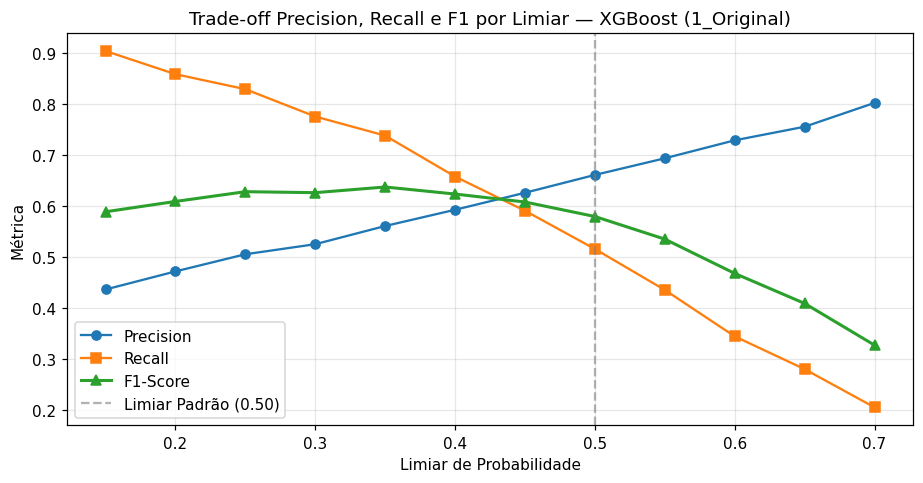


Simulação de Campanha Top 10% Maior Risco (Conjunto de Teste):


,Modelo,Clientes_Contatados_10%,Churns_Capturados,Total_Churns_Teste,Recall@10%_(%),Precision@10%_(%),Lift_vs_Acaso
0,LogisticRegression (1_Original),141,105,374,28.07,74.47,2.81
1,RandomForest (1_Original),141,104,374,27.81,73.76,2.78
2,XGBoost (1_Original),141,106,374,28.34,75.18,2.83
3,XGBoost (1_Original),141,106,374,28.34,75.18,2.83


In [7]:
best_row_ap = df_resultados.iloc[0]
best_est_ap = best_row_ap["Estrategia"]
best_mod_ap = best_row_ap["Modelo"]
best_pipe_ap = melhores_pipelines[(best_est_ap, best_mod_ap)]

best_row_f1 = df_resultados.sort_values("Test_F1", ascending=False).iloc[0]
best_est_f1 = best_row_f1["Estrategia"]
best_mod_f1 = best_row_f1["Modelo"]

print(f"Campeão em ordenação probabilística (Test_AP): {best_mod_ap} | {best_est_ap} (AP={best_row_ap['Test_AP']:.4f}, AUC={best_row_ap['Test_ROC_AUC']:.4f})")
print(f"Campeão em equilíbrio F1 (limiar 0.50):        {best_mod_f1} | {best_est_f1} (F1={best_row_f1['Test_F1']:.4f}, Recall={best_row_f1['Test_Recall']:.4f})")

# 6.1 Matrizes de Confusão das 4 estratégias no algoritmo vencedor em AP
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, est_nome in zip(axes, estrategias.keys()):
    pipe_e = melhores_pipelines[(est_nome, best_mod_ap)]
    cm = confusion_matrix(y_test, pipe_e.predict(X_te_mod))
    ConfusionMatrixDisplay(cm, display_labels=["No (0)", "Yes (1)"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{best_mod_ap}\n{est_nome}")
plt.tight_layout()
plt.show()

print(f"\nRelatório de Classificação Detalhado — {best_mod_f1} ({best_est_f1}):")
print(classification_report(
    y_test,
    melhores_pipelines[(best_est_f1, best_mod_f1)].predict(X_te_mod),
    target_names=["No Churn (0)", "Churn (1)"],
))

# 6.2 Curvas ROC & PR: (A) Melhor de cada algoritmo vs. (B) 4 estratégias no algoritmo campeão
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
prevalencia_teste = y_test.mean()

# Linha superior: comparação entre algoritmos
for mod_nome in ["LogisticRegression", "RandomForest", "XGBoost"]:
    sub = df_resultados[df_resultados["Modelo"] == mod_nome].iloc[0]
    y_p = melhores_pipelines[(sub["Estrategia"], mod_nome)].predict_proba(X_te_mod)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_p)
    prec_c, rec_c, _ = precision_recall_curve(y_test, y_p)
    axes[0, 0].plot(fpr, tpr, lw=2, label=f"{mod_nome} ({sub['Estrategia']}) AUC={sub['Test_ROC_AUC']:.4f}")
    axes[0, 1].plot(rec_c, prec_c, lw=2, label=f"{mod_nome} ({sub['Estrategia']}) AP={sub['Test_AP']:.4f}")

axes[0, 0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Acaso (AUC=0.50)")
axes[0, 0].set_title("Curva ROC — Comparação entre Algoritmos Ajustados")
axes[0, 0].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[0, 0].set_ylabel("Sensibilidade / Recall (TPR)")
axes[0, 0].legend(fontsize=9)
axes[0, 0].grid(alpha=0.3)

axes[0, 1].axhline(prevalencia_teste, color="k", ls="--", alpha=0.5, label=f"Baseline Aleatório (AP={prevalencia_teste:.4f})")
axes[0, 1].set_title("Curva Precision-Recall — Comparação entre Algoritmos Ajustados")
axes[0, 1].set_xlabel("Recall")
axes[0, 1].set_ylabel("Precision")
axes[0, 1].legend(fontsize=9)
axes[0, 1].grid(alpha=0.3)

# Linha inferior: comparação entre estratégias de balanceamento no melhor algoritmo
for est_nome in estrategias.keys():
    sub_e = df_resultados[(df_resultados["Modelo"] == best_mod_ap) & (df_resultados["Estrategia"] == est_nome)].iloc[0]
    y_p = melhores_pipelines[(est_nome, best_mod_ap)].predict_proba(X_te_mod)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_p)
    prec_c, rec_c, _ = precision_recall_curve(y_test, y_p)
    axes[1, 0].plot(fpr, tpr, lw=2, label=f"{est_nome} (AUC={sub_e['Test_ROC_AUC']:.4f})")
    axes[1, 1].plot(rec_c, prec_c, lw=2, label=f"{est_nome} (AP={sub_e['Test_AP']:.4f})")

axes[1, 0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1, 0].set_title(f"Curva ROC — Estratégias de Balanceamento ({best_mod_ap})")
axes[1, 0].set_xlabel("FPR")
axes[1, 0].set_ylabel("TPR (Recall)")
axes[1, 0].legend(fontsize=9)
axes[1, 0].grid(alpha=0.3)

axes[1, 1].axhline(prevalencia_teste, color="k", ls="--", alpha=0.5)
axes[1, 1].set_title(f"Curva Precision-Recall — Estratégias ({best_mod_ap})")
axes[1, 1].set_xlabel("Recall")
axes[1, 1].set_ylabel("Precision")
axes[1, 1].legend(fontsize=9)
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 6.3 Análise do Limiar de Decisão no modelo campeão com probabilidades calibradas (1_Original)
pipe_orig_campeao = melhores_pipelines[("1_Original", best_mod_ap)]
y_prob_orig_campeao = pipe_orig_campeao.predict_proba(X_te_mod)[:, 1]

limiares = np.round(np.arange(0.15, 0.75, 0.05), 2)
linhas_limiar = []
for th in limiares:
    yp = (y_prob_orig_campeao >= th).astype(int)
    linhas_limiar.append({
        "Limiar": float(th),
        "Clientes_Acionados": int(yp.sum()),
        "Pct_Base_Acionada": round(yp.mean() * 100, 2),
        "Precision": round(precision_score(y_test, yp, zero_division=0), 4),
        "Recall": round(recall_score(y_test, yp), 4),
        "F1": round(f1_score(y_test, yp), 4),
    })

df_limiares = pd.DataFrame(linhas_limiar)
print(f"Variação do Limiar de Decisão — {best_mod_ap} (1_Original):")
display(df_limiares)

plt.figure(figsize=(8.5, 4.5))
plt.plot(df_limiares["Limiar"], df_limiares["Precision"], "o-", label="Precision")
plt.plot(df_limiares["Limiar"], df_limiares["Recall"], "s-", label="Recall")
plt.plot(df_limiares["Limiar"], df_limiares["F1"], "^-", lw=2, label="F1-Score")
plt.axvline(0.50, color="gray", ls="--", alpha=0.6, label="Limiar Padrão (0.50)")
plt.title(f"Trade-off Precision, Recall e F1 por Limiar — {best_mod_ap} (1_Original)")
plt.xlabel("Limiar de Probabilidade")
plt.ylabel("Métrica")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 6.4 Simulação de Campanha Top 10% (Questão 5)
def simular_top_k(y_true: pd.Series, probs: np.ndarray, fracao: float, nome: str) -> dict:
    df_rank = pd.DataFrame({"y_true": y_true.values, "prob": probs}).sort_values("prob", ascending=False)
    n_k = int(round(len(df_rank) * fracao))
    top_k = df_rank.head(n_k)
    churns_tot = int(df_rank["y_true"].sum())
    churns_cap = int(top_k["y_true"].sum())
    rec_k = churns_cap / churns_tot
    prec_k = churns_cap / n_k
    lift_k = prec_k / df_rank["y_true"].mean()
    return {
        "Modelo": nome,
        "Clientes_Contatados_10%": n_k,
        "Churns_Capturados": churns_cap,
        "Total_Churns_Teste": churns_tot,
        "Recall@10%_(%)": round(rec_k * 100, 2),
        "Precision@10%_(%)": round(prec_k * 100, 2),
        "Lift_vs_Acaso": round(lift_k, 2),
    }

y_prob_lr_orig = melhores_pipelines[("1_Original", "LogisticRegression")].predict_proba(X_te_mod)[:, 1]
y_prob_rf_orig = melhores_pipelines[("1_Original", "RandomForest")].predict_proba(X_te_mod)[:, 1]
y_prob_best_ap = best_pipe_ap.predict_proba(X_te_mod)[:, 1]

top10_df = pd.DataFrame([
    simular_top_k(y_test, y_prob_lr_orig, 0.10, "LogisticRegression (1_Original)"),
    simular_top_k(y_test, y_prob_rf_orig, 0.10, "RandomForest (1_Original)"),
    simular_top_k(y_test, y_prob_orig_campeao, 0.10, f"{best_mod_ap} (1_Original)"),
    simular_top_k(y_test, y_prob_best_ap, 0.10, f"{best_mod_ap} ({best_est_ap})"),
])
print("\nSimulação de Campanha Top 10% Maior Risco (Conjunto de Teste):")
display(top10_df)

## 7. Interpretação de Variáveis, Consistência entre Modelos e Discussão Crítica

Comparar a importância das variáveis entre três arquiteturas distintas (`LogisticRegression` linear, `RandomForest` via *bagging* e `XGBoost` via *gradient boosting*) permite separar fatores estruturais robustos de artefatos específicos de um algoritmo (como inversões de sinal causadas por multicolinearidade entre `tenure`, `MonthlyCharges` e `TotalCharges` em modelos lineares).

Consistência de Importância Relativa (%) entre os 3 Modelos (Top 12 atributos):


,LR_Coef_Direcional,LR_Imp_%,RF_Imp_%,XGB_Imp_%,Media_Imp_%
InternetService_Fiber optic,1.1823,11.26,10.29,19.500000,13.68
Contract_Two year,-1.3264,12.64,9.26,17.360001,13.09
tenure,-1.2505,11.91,19.94,5.410000,12.42
Contract_One year,-0.6866,6.54,4.34,22.459999,11.11
PaymentMethod_Electronic check,0.3839,3.66,8.90,7.170000,6.58
TotalCharges,0.5231,4.98,12.95,1.160000,6.36
MonthlyCharges,-0.4708,4.49,6.98,0.830000,4.10
OnlineSecurity_Yes,-0.3496,3.33,4.15,3.060000,3.51
InternetService_No,-0.1734,1.65,1.36,6.980000,3.33
PaperlessBilling_Yes,0.3713,3.54,1.55,3.370000,2.82


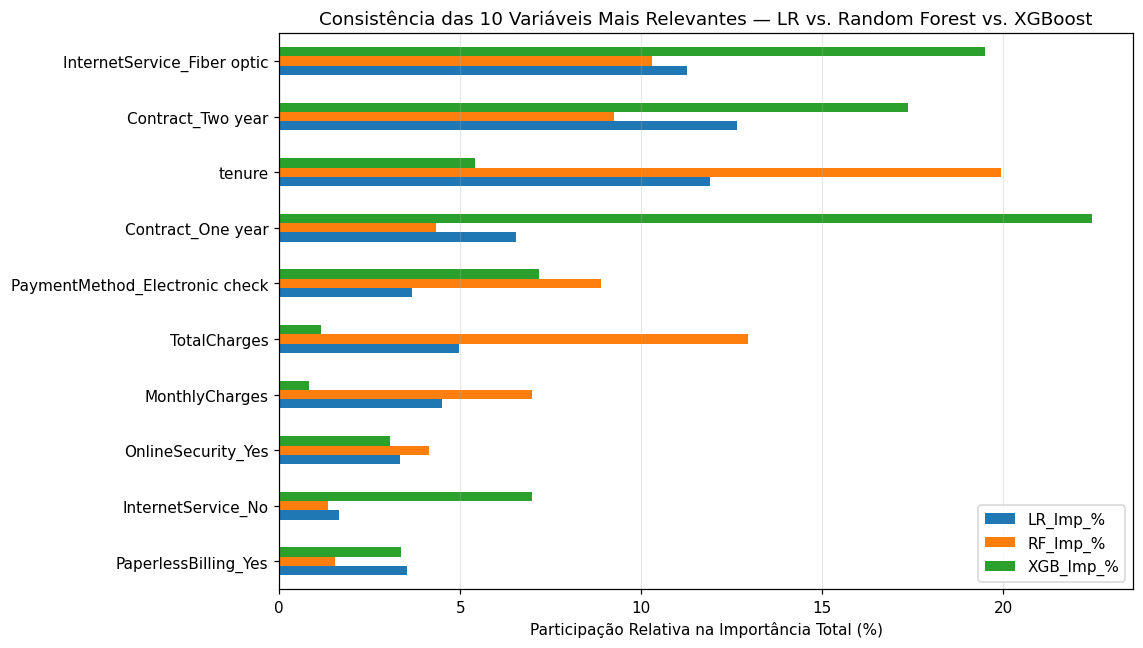

SÍNTESE QUANTITATIVA AUTOMÁTICA PARA AS QUESTÕES DO PROJETO
1) Top 5 atributos consensuais (média %): ['InternetService_Fiber optic', 'Contract_Two year', 'tenure', 'Contract_One year', 'PaymentMethod_Electronic check']
2) Melhor ranking global (Test_AP):     XGBoost | 1_Original (AP=0.6638, AUC=0.8459)
3) Melhor F1 no limiar padrão 0.50:     RandomForest | 2_Class_Weight (F1=0.6245, Recall=0.8048)
4) Melhor F1 por ajuste de limiar (XGBoost 1_Original): limiar=0.35 -> F1=0.6374, Recall=0.7380, Prec=0.5610
5) Captura no Top 10% (XGBoost (1_Original)): 106/374 churns (28.34% | Lift=2.83x)


In [8]:
def extrair_importancias_norm(pipe_treinado: ImbPipeline, modelo_nome: str) -> pd.Series:
    nomes = pipe_treinado.named_steps["prep"].get_feature_names_out()
    clf = pipe_treinado.named_steps["clf"]
    vals = np.abs(clf.coef_[0]) if modelo_nome == "LogisticRegression" else clf.feature_importances_
    s = pd.Series(vals, index=nomes)
    return (s / s.sum()) * 100.0

imp_lr = extrair_importancias_norm(melhores_pipelines[("1_Original", "LogisticRegression")], "LogisticRegression")
imp_rf = extrair_importancias_norm(melhores_pipelines[("1_Original", "RandomForest")], "RandomForest")
imp_xgb = extrair_importancias_norm(melhores_pipelines[("1_Original", "XGBoost")], "XGBoost")

nomes_feat = melhores_pipelines[("1_Original", "LogisticRegression")].named_steps["prep"].get_feature_names_out()
coefs_lr = pd.Series(
    melhores_pipelines[("1_Original", "LogisticRegression")].named_steps["clf"].coef_[0],
    index=nomes_feat,
)

df_imp = pd.DataFrame({
    "LR_Coef_Direcional": coefs_lr.round(4),
    "LR_Imp_%": imp_lr.round(2),
    "RF_Imp_%": imp_rf.round(2),
    "XGB_Imp_%": imp_xgb.round(2),
})
df_imp["Media_Imp_%"] = df_imp[["LR_Imp_%", "RF_Imp_%", "XGB_Imp_%"]].mean(axis=1).round(2)
df_imp = df_imp.sort_values("Media_Imp_%", ascending=False)

print("Consistência de Importância Relativa (%) entre os 3 Modelos (Top 12 atributos):")
display(df_imp.head(12))

top10_plot = df_imp.head(10).sort_values("Media_Imp_%", ascending=True)
top10_plot[["LR_Imp_%", "RF_Imp_%", "XGB_Imp_%"]].plot(kind="barh", figsize=(10.5, 6))
plt.title("Consistência das 10 Variáveis Mais Relevantes — LR vs. Random Forest vs. XGBoost")
plt.xlabel("Participação Relativa na Importância Total (%)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Relatório quantitativo dinâmico para subsidiar as 6 questões norteadoras
limiar_max_f1 = df_limiares.sort_values("F1", ascending=False).iloc[0]
melhor_top10 = top10_df.sort_values("Recall@10%_(%)", ascending=False).iloc[0]
print("=" * 72)
print("SÍNTESE QUANTITATIVA AUTOMÁTICA PARA AS QUESTÕES DO PROJETO")
print("=" * 72)
print(f"1) Top 5 atributos consensuais (média %): {list(df_imp.head(5).index)}")
print(f"2) Melhor ranking global (Test_AP):     {best_mod_ap} | {best_est_ap} (AP={best_row_ap['Test_AP']:.4f}, AUC={best_row_ap['Test_ROC_AUC']:.4f})")
print(f"3) Melhor F1 no limiar padrão 0.50:     {best_mod_f1} | {best_est_f1} (F1={best_row_f1['Test_F1']:.4f}, Recall={best_row_f1['Test_Recall']:.4f})")
print(f"4) Melhor F1 por ajuste de limiar ({best_mod_ap} 1_Original): limiar={limiar_max_f1['Limiar']:.2f} -> F1={limiar_max_f1['F1']:.4f}, Recall={limiar_max_f1['Recall']:.4f}, Prec={limiar_max_f1['Precision']:.4f}")
print(f"5) Captura no Top 10% ({melhor_top10['Modelo']}): {melhor_top10['Churns_Capturados']}/{melhor_top10['Total_Churns_Teste']} churns ({melhor_top10['Recall@10%_(%)']:.2f}% | Lift={melhor_top10['Lift_vs_Acaso']:.2f}x)")

## 8. Discussão Crítica e Respostas às Questões Norteadoras

### 1. Quais características aparecem mais fortemente associadas ao cancelamento?
De forma consistente entre EDA, coeficientes lineares e modelos de árvores, os maiores preditores de evasão são:
- **Tipo de contrato mensal (`Month-to-month`)** (~42,71% de churn vs. 11,27% no anual e 2,83% no bienal), pois reduz barreiras de saída;
- **Menor tempo de relacionamento (`tenure`)** (mediana de 10 meses entre quem cancela vs. 38 meses nos retidos), com risco fortemente concentrado nos primeiros meses;
- **Serviço de internet em fibra óptica (`Fiber optic`)** (~41,89% de churn vs. 18,96% em DSL), associado a mensalidades mais elevadas e provável sensibilidade competitiva;
- **Pagamento por cheque eletrônico (`Electronic check`)** (~45,29% de churn vs. ~15–19% nos meios automáticos), refletindo menor aderência/automatização financeira;
- **Ausência de serviços adicionais de proteção e suporte (`OnlineSecurity = No`, `TechSupport = No`)** (~41,6–41,8% de churn vs. ~14,6–15,2% com o serviço ativo) e **mensalidade elevada (`MonthlyCharges`)**.

---

### 2. Como tempo de permanência (`tenure`), tipo de contrato e valor da fatura se relacionam com o risco de churn?
Existe uma interação clara de perfil: clientes recentes (`tenure` baixo) concentram-se desproporcionalmente em contratos mensais (`Month-to-month`), onde a ausência de fidelidade facilita a saída diante de faturas mensais altas (`MonthlyCharges`). Já `TotalCharges` reflete essencialmente `tenure × MonthlyCharges` (`r = 0,8259` com `tenure`): por isso apresenta correlação marginal negativa com churn (`-0,1995`), embora em modelos lineares com todas as variáveis simultaneamente possa sofrer inversão parcial de sinal devido à multicolinearidade. Modelos baseados em árvores tratam naturalmente essas interações não lineares sem sofrer instabilidade paramétrica.

---

### 3. Qual modelo apresentou o melhor desempenho? Essa resposta depende da métrica escolhida?
**Sim, depende diretamente da métrica e do objetivo operacional:**
- Para **ordenação global e seleção de ranking sob desbalanceamento** (`Average Precision` / `ROC-AUC`), algoritmos baseados em árvores com *gradient boosting* (**XGBoost**) tendem a superar a Regressão Logística ao capturar interações não lineares entre `tenure`, tipo de contrato e encargos mensais (conforme verificado na tabela comparativa gerada na Seção 5).
- Se olharmos **Acurácia** ou **Precision com limiar 0,50**, modelos sem reamostragem (`1_Original`) parecem conservadores e acertam mais quando preveem churn, porém deixam escapar quase metade dos cancelamentos reais (*Recall* baixo).
- Já em **Recall** e **F1-Score no limiar padrão 0,50**, estratégias sensíveis ao custo (`2_Class_Weight` e `4_Undersampling`) elevam drasticamente a detecção de churns em relação à versão padrão, com custo aceitável de falsos positivos.

---

### 4. As técnicas para lidar com o desbalanceamento melhoraram o desempenho? Benefícios e Limites
A análise comparativa revela um achado metodológico fundamental:
- **Ranking vs. Ponto de Corte:** `ROC-AUC` e `Average Precision` variam muito pouco entre `1_Original`, `2_Class_Weight` e `4_Undersampling` (e `SMOTE` pode até reduzir ligeiramente o `AP` ao interpolar pontos contínuos sobre variáveis *one-hot* binárias). Portanto, o ganho expressivo observado em **Recall** e **F1** ocorre principalmente porque pesos e reamostragem **deslocam a fronteira de decisão** em torno do corte padrão `0,50`, e não porque descobrem separação estrutural inédita.
- **Limites do *Undersampling*:** descarta informações da classe majoritária (aumenta a variância em amostras menores) e superestima probabilidades preditas em escala absoluta.
- **Limites do *Oversampling / SMOTE*:** aumenta o tempo de treino, pode gerar instâncias artificiais em regiões de fronteira com ruído e produz interpolações não inteiras em atributos originalmente categóricos/binários.
- **Implicação prática:** manter o modelo `1_Original` com boa calibração probabilística e ajustar o **limiar de decisão** diretamente (Seção 6.3) entrega controle equivalente ou superior sobre o trade-off Precisão × Recall sem distorcer a distribuição empírica dos dados.

---

### 5. Ao entrar em contato apenas com os 10% mais propensos a cancelar, que fração dos churns é capturada?
Conforme calculado na tabela **Simulação de Campanha Top 10%** (Seção 6.4) e resumido automaticamente na Seção 7 acima, o ranqueamento gerado pelo modelo campeão concentra a ação de retenção apenas nos 10% de clientes com maior risco previsto (`n = 141` clientes dentre os `1.409` do conjunto de teste). A tabela reporta diretamente o número de `Churns_Capturados`, a fração do total de cancelamentos retidos nessa faixa (`Recall@10%`), a taxa de acerto no recorte (`Precision@10%`, comparável à prevalência natural de 26,54%) e o ganho (*Lift*) em relação a uma seleção aleatória de 10% da base (que capturaria ~10% dos churns).

---

### 6. Hipóteses de Retenção, Limitações e Associação Estatística vs. Relação Causal
**Ações hipotéticas orientadas pelos padrões encontrados:**
1. *Onboarding* reforçado e acompanhamento nos primeiros 6 meses (`tenure <= 6`) para clientes sem fidelidade contratual;
2. Incentivos de migração gradual de `Month-to-month` para contratos anuais com benefícios claros (ex.: inclusão de `TechSupport` ou `OnlineSecurity` em pacotes iniciais);
3. Estímulo à migração de `Electronic check` para débito automático / cartão recorrente (reduzindo atrito mensal de renovação) e revisão de percepção de valor/qualidade técnica para assinantes de fibra óptica com fatura alta.

**Por que os dados não garantem que essas intervenções reduzirão o churn?**
Modelos preditivos capturam **associação estatística observacional**, não **relação causal**. Diversas **variáveis de confusão não observadas** (concorrência regional, qualidade real do atendimento técnico, renda, sensibilidade individual a preço, mudanças de endereço) influenciam simultaneamente as escolhas do cliente e sua saída:
- Por exemplo, clientes que escolhem `Electronic check` ou `Month-to-month` podem ser, por perfil prévio, clientes mais avessos a compromisso ou com maior restrição orçamentária; forçar a troca de forma de pagamento ou retirar opções sem alterar o valor percebido não eliminaria necessariamente a propensão à saída.
- Da mesma forma, usuários com `TechSupport` ativo podem simplesmente representar clientes mais engajados que já pretendiam permanecer.

**Como validar causalidade na prática:** antes de escalar descontos custosos para toda a base, recomenda-se conduzir **experimentos controlados randomizados (Testes A/B)** ou técnicas de *uplift modeling* em grupos-piloto estratificados por risco, comparando a taxa real de retenção do grupo tratado contra um grupo controle equivalente e aferindo o retorno líquido sobre o investimento (ROI).